**Human Movement Intelligence | Biomechanical Load Estimation | Presented by: Reza Saadatyar (2026)**

**08 | Frozen Final Model Evaluation and Research Synthesis**

![Completed source-verified final Essex study: seven IMUs, frozen Random Forest primary, descriptive TCN, and one-time Test evaluation](../../images/08_consolidated_workflow.svg)

**Final research question:** Following seven development stages, how well do the two **pre-frozen models** predict original model-derived e1/e3 femoral-neck finite-element (FE) strain trajectories on **four previously unseen Test participants** from the same Essex source cohort, and what can be learned from waveform, peak magnitude and peak location errors?

**Source and governance:** Original Essex Figshare v13 contained 1,897 trials; **1,729** had eligible source-matched IMU and FE records from **37 participants**. Original IMU trial input is 101×42 (seven six-channel lower-body sensors); published unitless FE target is 11×2 at **eleven original matched source positions**, with no FE interpolation or physical unit conversion. Subject-disjoint splits remained Training **29/1,354**, Validation **4/192** and frozen Test **4/183**. After Training-only model selection, exactly **33 development participants (1,546 trials)** were used to fit the final models.

**Frozen-before-Test selection:** Stages 05 and 07 selected the **Random Forest primary** from Training-only participant-disjoint CV (subject-balanced MAE **0.0007950**) before Test access. A **Dilated TCN secondary** was declared in the separately committed [frozen final protocol](../../output/08_frozen_final_protocol.json) for descriptive waveform and peak comparison. Both were fit **once** on Training+Validation, using the frozen recipes. The recorded device was Tesla T4 with CUDA for the TCN; Random Forest retained 200 trees and 210 original-channel statistical predictors. Test outcomes **did not change** the primary model.

**Final Test results:** On the 183 previously reserved trials, primary Random Forest reached **subject-balanced waveform MAE 0.0009384**; the fixed secondary Dilated TCN reached **0.0008759**, approximately **6.7% lower observed error**. Dilated TCN had lower target-wise waveform and peak-*value* error for both e1 and e3, while Random Forest had lower peak-*position* error for both. The paired, four-participant exploratory 95% bootstrap interval for **TCN − RF waveform MAE** was **[−0.0001859, +0.0000431]**, crossing zero; this does not establish a population-wide or confirmatory advantage.

**Final execution and reporting status:** All **11 code cells executed without saved errors**, one-time Test release is recorded, **16 public `08_*` files** are committed and the Stage 08 Quality Gate reports **PASSED**. Test evaluation was conducted once under the pre-frozen protocol; no post-Test tuning, model promotion or additional external dataset was involved. The outcomes remain **unitless FE-model estimates**, not measured in-vivo strains, clinical predictions or evidence of deployment readiness.

**Portfolio handover:** The complete 01–08 research pathway and final Test findings are documented in the [project README](../../README.md). The originally inspected BoneNet derivative pilot is a separate, historical analysis with different data-linkage and scale limitations and must not be conflated with this fully source-verified Essex study.


**00. Colab Repository Setup**

The recorded execution synchronised the approved GitHub repository before running the final evaluation. The executed notebook and its stored outputs are retained as **historical evidence**. Do not rerun the one-time Test release cell or refit models in an attempt to change the reported final outcome.


In [1]:
# ======================== 00. Colab Repository Setup =========================

# ------------------------- 1. Research Repository ----------------------------
from pathlib import Path
import importlib
import subprocess
import sys

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_branch = "main"
repo_path = Path("/content") / repo_url.rsplit("/", 1)[-1].removesuffix(".git")

# ------------------------- 2. Initial Repository Clone -----------------------
if not repo_path.exists():
    subprocess.run(
        ["git", "clone", "--branch", repo_branch, repo_url, str(repo_path)],
        check=True,
    )

# ------------------- 3. Safe Synchronisation and Module Refresh --------------
if str(repo_path) not in sys.path:
    sys.path.insert(0, str(repo_path))

from python_modules.core import repository_sync
importlib.reload(repository_sync)

# One-time migration of checkouts containing the original sync helper.
if not hasattr(repository_sync, "prepare_notebook_repository"):
    try:
        repository_sync.sync_repository(
            repo_url, repo_branch, parent=repo_path.parent,
        )
    except RuntimeError as exc:
        # The older helper raises only AFTER a successful fast-forward.
        if not str(exc).startswith(
            "Repository files updated successfully, but Python"
        ):
            raise
    importlib.invalidate_caches()
    importlib.reload(repository_sync)

repo_path = repository_sync.prepare_notebook_repository(
    repo_url, "biomechanical_load_estimation", branch=repo_branch,
    parent=repo_path.parent,
    sync_mode="update", module_refresh="auto", data_mode="reuse",
)

# ---------------------------- 4. Open Repository -----------------------------
%cd {repo_path}


Repository updated.
/content/human-movement-intelligence


**01. Imports, Shared Device and Final Research Environment**

The study used the shared `computer_device()` helper, as in HARTH. The recorded environment was a **Tesla T4 CUDA GPU** for the secondary PyTorch Dilated TCN; the primary scikit-learn Random Forest used its normal CPU estimator implementation. The final evidence reports PyTorch **2.11.0+cu130**, scikit-learn **1.6.1** and original target units as **unitless**.


In [2]:
# ================== 01. Frozen Final Research Environment ===================
from python_modules.core.colab_setup import setup_colab
root = setup_colab("biomechanical_load_estimation")

import hashlib
import json
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure
from core.output_download import download_outputs_from_colab
from core.computer_device import computer_device
from essex_figshare import (
    ARTICLE_ID, ARTICLE_VERSION, ensure_pinned_matlab_archive,
    inspect_matlab_archive, extract_matlab_files,
)
from essex_numeric_recovery import check_record_registry
from essex_paired_dataset import (
    build_paired_arrays, paired_source_digest, save_ignored_cache,
)
from essex_timebase_audit import EXPECTED_CHANNELS
from essex_temporal_regression import check_temporal_arrays
from essex_regression_baselines import (
    regression_metrics, participant_metrics, trial_predictions,
    subject_balanced_mae,
)
from essex_stage08_final import (
    EXPECTED_PRIMARY, SECONDARY, PROTOCOL_FILE, FINAL_GATE_FILE,
    RELEASE_PHRASE, file_sha256, load_frozen_protocol,
    fit_frozen_primary, predict_frozen_primary,
    fit_frozen_secondary, predict_frozen_secondary,
    release_one_time_test, participant_bootstrap, paired_test_bootstrap,
)

plot_style(font_family="DejaVu Sans", title_size=12.5,
    title_weight="normal", label_size=11.5, label_weight="normal",
    tick_size=11, legend_size=10, figure_dpi=100, figure_size=(9, 4))

study_dir = root / "biomechanical_load_estimation"
raw_dir = root / "data" / "raw" / "essex_femoral_neck_loading"
mat_dir = raw_dir / "matlab_records"
processed_dir = root / "data" / "processed" / "essex_femoral_neck_loading"
output_dir = study_dir / "output"
ledger_dir = processed_dir / "stage08_one_time_release"
output_dir.mkdir(parents=True, exist_ok=True)
processed_dir.mkdir(parents=True, exist_ok=True)

# The common helper reports OS, RAM, GPU, VRAM and PyTorch CUDA readiness.
device = computer_device()
DEVICE = device.type
print("Frozen primary: Random Forest | secondary: Dilated TCN")
print("Scientific output directory:", output_dir)


Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu130
CUDA device: Tesla T4
CUDA runtime: 13.0
cuDNN version: 92700
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
Frozen primary: Random Forest | secondary: Dilated TCN
Scientific output directory: /content/human-movement-intelligence/biomechanical_load_estimation/output


**02. Verify Frozen Model Decision, Participant Roles and Provenance**

All upstream source and Stage 04/05/07 quality gates were verified. The separately committed final protocol was checked **before** opening the four reserved Test participants. Training-only evidence fixed Random Forest as primary, Dilated TCN as secondary, and 1,546 Development versus 183 Test trials. The original source hashes and participant identities were consistent with the earlier source audit.


In [3]:
# ================== 02. Pinned Stage 04 Evidence and Splits ===================
# -------------------------- 1. Load Saved Evidence --------------------------
paths04 = {
    "gate": output_dir / "04_dataset_and_split_quality_gate.json",
    "manifest": output_dir / "04_local_dataset_build_manifest.json",
    "trials": output_dir / "04_trial_split_assignments.csv",
    "subjects": output_dir / "04_subject_split_assignments.csv",
    "source": output_dir / "01_consolidated_source_and_trial_quality_gate.json",
    "registry": output_dir / "01_original_record_registry.csv",
    "mapping": output_dir / "03_original_time_coordinate_mapping.csv",
}
missing04 = [key for key, path in paths04.items() if not path.is_file()]
if missing04:
    raise FileNotFoundError("Missing committed upstream evidence: " +
                            ", ".join(missing04))
gate04 = json.loads(paths04["gate"].read_text(encoding="utf-8"))
manifest04 = json.loads(paths04["manifest"].read_text(encoding="utf-8"))
source01 = json.loads(paths04["source"].read_text(encoding="utf-8"))
assigned = pd.read_csv(paths04["trials"], dtype=str)
subjects04 = pd.read_csv(paths04["subjects"], dtype=str)
assert gate04["stage04_quality_gate"] == "PASSED"
assert gate04["source_article_id"] == ARTICLE_ID == 30225739
assert gate04["source_version"] == ARTICLE_VERSION == 13
assert gate04["original_sha256"] == source01["archive_sha256"]
assert gate04["original_sha256"] == manifest04["original_archive_sha256"]
assert gate04["canonical_pair_sha256"] == manifest04["canonical_pair_sha256"]
assert manifest04["feature_shape"] == [1729, 101, 42]
assert manifest04["target_shape"] == [1729, 11, 2]
assert gate04["original_source_empty_fe"] == 168
assert gate04["original_target_units_as_published"] == "unitless"

# ------------------------ 2. Freeze Participant Roles -----------------------
expected_splits = {"TRAIN": 1354, "VALIDATION": 192, "TEST": 183}
assert assigned["split"].value_counts().to_dict() == expected_splits
assert assigned["local_record_key"].is_unique
assert len(assigned) == 1729
assert subjects04["subject_id"].is_unique
assert subjects04["split"].value_counts().to_dict() == {
    "TRAIN": 29, "VALIDATION": 4, "TEST": 4,
    "EXCLUDED_NO_FE_TARGET": 3,
}
assert assigned.groupby("subject_id")["split"].nunique().eq(1).all()
assert assigned["split"].eq(
    assigned["subject_id"].map(subjects04.set_index("subject_id")["split"])
).all()
train_mask = assigned["split"].eq("TRAIN").to_numpy()
valid_mask = assigned["split"].eq("VALIDATION").to_numpy()
test_mask = assigned["split"].eq("TEST").to_numpy()
assert not np.any(train_mask & valid_mask)
assert not np.any(train_mask & test_mask)
assert not np.any(valid_mask & test_mask)
print("Frozen Training trials:", train_mask.sum())
print("Frozen Validation trials:", valid_mask.sum())
print("Reserved Test trials (no model access):", test_mask.sum())



# ------------------------- 3. Check Final Freeze -----------------------------
required = {
    "stage05": output_dir / "05_regression_protocol_and_quality_gate.json",
    "stage06": output_dir / "06_temporal_protocol_and_quality_gate.json",
    "stage07": output_dir / "07_robustness_protocol_and_quality_gate.json",
    "decision": output_dir / "07_training_candidate_decision.csv",
    "freeze": output_dir / PROTOCOL_FILE,
}
for key, path in required.items():
    if not path.is_file():
        raise FileNotFoundError(f"Missing prerequisite {key}: {path}")
gate05 = json.loads(required["stage05"].read_text(encoding="utf-8"))
gate06 = json.loads(required["stage06"].read_text(encoding="utf-8"))
gate07 = json.loads(required["stage07"].read_text(encoding="utf-8"))
decision = pd.read_csv(required["decision"])
primary_row = decision.loc[decision["training_cv_selected"].eq(True)]
assert len(primary_row) == 1
assert gate06["quality_gate"] == "PASSED"
assert gate06["canonical_pair_sha256"] == gate04["canonical_pair_sha256"]
protocol, protocol_sha256 = load_frozen_protocol(
    required["freeze"], gate04, gate05, gate07,
    primary_row.iloc[0],
)
assert protocol["source_article_id"] == ARTICLE_ID == 30225739
assert protocol["source_version"] == ARTICLE_VERSION == 13
assert assigned["split"].value_counts().to_dict() == {
    "TRAIN": 1354, "VALIDATION": 192, "TEST": 183,
}
dev_mask = train_mask | valid_mask
assert dev_mask.sum() == 1546 and test_mask.sum() == 183
dev_info = assigned.loc[dev_mask].reset_index(drop=True)
test_info = assigned.loc[test_mask].reset_index(drop=True)
assert dev_info["subject_id"].nunique() == 33
assert test_info["subject_id"].nunique() == 4
assert set(dev_info["subject_id"]).isdisjoint(set(test_info["subject_id"]))
assert test_info["local_record_key"].is_unique
print("Pre-Test model selection: LOCKED", protocol["locked_primary_candidate"])
print("Frozen protocol SHA256:", protocol_sha256)
print("Development: 33 participants / 1546 trials")
print("Reserved Test: 4 participants / 183 trials (unopened)")


Frozen Training trials: 1354
Frozen Validation trials: 192
Reserved Test trials (no model access): 183
Pre-Test model selection: LOCKED Random Forest (Stage 05 locked)
Frozen protocol SHA256: 7fbcd18864d193a7b4c8372ad3f4e51d0260c225b43698eca9a21cff0ad4929a
Development: 33 participants / 1546 trials
Reserved Test: 4 participants / 183 trials (unopened)


**03. Reconstruct Source-Exact Cache and Materialise Development Only**

The recorded execution verified the source-archive and paired-cache lineage, reusing the existing Git-ignored numeric cache. It copied only **Training+Validation** signals and targets for the final model fits, preserving the **101×42 IMU / 11×2 native FE** structure. Test arrays were not used for fitting and were first materialised only after the explicit one-time release was authorised.


In [4]:
# ============== 03. Verified Cache and Source Reconstruction ================
# ------------------- 1. Pinned Original MATLAB Reader -----------------------
%pip -q install --only-binary=:all: --no-deps "mat-io==1.0.1"
from matio import load_from_mat
assert version("mat-io") == "1.0.1"

# --------------------- 2. Rebuild Cache Only If Missing ----------------------
cache_path = processed_dir / "essex_imu_fe_pairs_v13.npz"
if not cache_path.exists():
    archive, hashes = ensure_pinned_matlab_archive(raw_dir)
    assert hashes["sha256"] == source01["archive_sha256"]
    inventory = inspect_matlab_archive(archive, expected_mat_files=40)
    mat_files = extract_matlab_files(archive, mat_dir, inventory)
    assert len(mat_files) == 40
    registry = pd.read_csv(paths04["registry"], dtype={
        "local_record_key": str, "source_file": str,
        "subject_id": str, "task": str, "updated_trial_id": str,
        "fe_representation": str,
    })
    mapping = pd.read_csv(paths04["mapping"], dtype={
        "local_record_key": str, "imu_position_indices": str,
        "mapping_status": str,
    })
    check_record_registry(registry, source01)
    rebuilt, eligible, excluded = build_paired_arrays(
        load_from_mat, mat_dir, registry, mapping, source01,
    )
    assert len(eligible) == 1729 and len(excluded) == 168
    assert eligible["local_record_key"].tolist() == (
        assigned["local_record_key"].tolist()
    )
    assert paired_source_digest(rebuilt, assigned) == (
        gate04["canonical_pair_sha256"]
    )
    save_ignored_cache(cache_path, rebuilt, assigned)
    del rebuilt, eligible, excluded
    print("Source-verified local cache reconstructed.")
else:
    print("Using existing Stage 04 cache, subject to fingerprint verification.")

# ---------------------- 3. Verify Cached Source Identity --------------------
with np.load(cache_path, allow_pickle=False) as saved:
    assert set(saved.files) == {
        "X_full", "X_at_fe", "y_fe", "imu_positions", "record_keys"
    }
    assert saved["record_keys"].astype(str).tolist() == (
        assigned["local_record_key"].tolist()
    )
    # Original Test source values are included ONLY in this integrity digest;
    # no Test feature/target is supplied to any estimator or metric below.
    source_digest = paired_source_digest(
        {key: saved[key] for key in (
            "X_full", "X_at_fe", "y_fe", "imu_positions"
        )}, assigned,
    )
    assert source_digest == gate04["canonical_pair_sha256"]
    x_development = saved["X_full"][dev_mask].copy()
    idx_development = saved["imu_positions"][dev_mask].copy()
    y_development = saved["y_fe"][dev_mask].copy()
assert x_development.shape == (1546, 101, 42)
assert idx_development.shape == (1546, 11)
assert y_development.shape == (1546, 11, 2)
check_temporal_arrays(x_development, idx_development, y_development)
print("Canonical source fingerprint: VERIFIED")
print("Only Development observations materialised before Test release.")


Using existing Stage 04 cache, subject to fingerprint verification.
Canonical source fingerprint: VERIFIED
Only Development observations materialised before Test release.


**04. Freeze Data Feature Contracts and Evaluation Rules**

All pre-inference checks passed: **210 target-independent IMU predictors** for the Random Forest, exact original FE target geometry for Dilated TCN, **33 Development** and **four Test** participants without overlap, and the predeclared one-round Test metric schema. No hyperparameters or thresholds were selected using Test data.


In [5]:
# =================== 04. Final Development Protocol Checks ===================
from essex_regression_baselines import trial_features, flatten_targets

development_subjects = set(dev_info["subject_id"])
reserved_subjects = set(test_info["subject_id"])
assert len(development_subjects) == 33
assert len(reserved_subjects) == 4
assert not development_subjects & reserved_subjects
assert len(set(dev_info["local_record_key"])) == len(dev_info)
assert not set(dev_info["local_record_key"]) & set(
    test_info["local_record_key"]
)
features_dev, original_feature_names = trial_features(
    x_development, EXPECTED_CHANNELS
)
targets_dev = flatten_targets(y_development)
assert features_dev.shape == (1546, 210)
assert targets_dev.shape == (1546, 22)
assert protocol["final_fitting_policy"]["no_new_tuning_or_model_selection"]
assert protocol["primary_model"]["random_state"] == 2026
assert protocol["secondary_model"]["seed"] == 2128
assert protocol["secondary_model"]["epochs"] == 35
assert protocol["single_final_evaluation"]["evaluation_rounds"] == 1
print("Frozen development and model contracts: PASSED")
print("TEST data not materialised; no model selection remains.")


Frozen development and model contracts: PASSED
TEST data not materialised; no model selection remains.


**05. Fit Both Frozen Models Exactly Once on Development**

The full-development final fits completed on **1,546 trials** (33 participants). The primary Random Forest contained **200 trees**, with five statistics per 42 IMU channels (210 features). The fixed secondary Dilated TCN contained **51,986 trainable parameters** and completed its prescribed **35 epochs** using the original FE positions. The saved fitting manifest documents the actual estimator settings and compute environment. These are new final-development fits; their Test results must not be directly equated with earlier Validation results from differently fitted models.


In [6]:
# =============== 05. Train Frozen Development Models Once ===================
primary, primary_features = fit_frozen_primary(
    x_development, y_development, EXPECTED_CHANNELS, protocol
)
secondary, secondary_scaler, final_training_history = fit_frozen_secondary(
    x_development, y_development, idx_development,
    protocol, device=device,
)
assert len(primary.estimators_) == 200
assert primary.n_outputs_ == 22
assert len(final_training_history) == 35
assert np.isfinite(final_training_history["training_loss"]).all()
secondary_parameters = sum(p.numel() for p in secondary.parameters())
model_manifest = {
    "stage": "08",
    "frozen_protocol_sha256": protocol_sha256,
    "model_selection_dataset": "TRAIN_OOF_ONLY",
    "development_subjects": 33,
    "development_trials": 1546,
    "original_imu_shape": [101, 42],
    "original_fe_shape": [11, 2],
    "primary": {
        "name": EXPECTED_PRIMARY,
        "trees": len(primary.estimators_),
        "features": len(primary_features),
        "seed": 2026,
    },
    "secondary": {
        "name": SECONDARY,
        "trainable_parameters": secondary_parameters,
        "epochs": len(final_training_history),
        "seed": 2128,
        "role": "secondary_only_no_test_promotion",
    },
    "selected_pytorch_device": DEVICE,
    "scikit_learn_version": version("scikit-learn"),
    "torch_version": torch.__version__,
}
print("FROZEN DEVELOPMENT FIT COMPLETE")
print("RF estimators:", len(primary.estimators_))
print("TCN parameters:", secondary_parameters)
print("The reserved Test set is still sealed.")


FROZEN DEVELOPMENT FIT COMPLETE
RF estimators: 200
TCN parameters: 51986
The reserved Test set is still sealed.


**06. Explicit One-Time Test Release — Authorised and Consumed**

**Recorded final status:** The previously protected one-time Test release was explicitly authorised during this genuine run, and the committed receipt reports `TEST_RELEASE_CONSUMED`. Both model identities and recipes had already been frozen and committed before that release. The release ledger is a local safety mechanism, not an enforceable worldwide lock. **Do not rerun the release or Test-scoring cells** to obtain a different outcome. The executed code and the original receipt are preserved without alteration.


In [7]:
# ================== 06. Explicit One-Time Test Release ======================
# Read the already committed frozen protocol before granting release.
print("Primary model:", protocol["locked_primary_candidate"])
print("Frozen protocol SHA256:", protocol_sha256)
print("Development fits completed:", len(primary.estimators_) == 200
      and len(final_training_history) == 35)
print("To authorise one-time Test evaluation, set:")
print('FINAL_TEST_APPROVAL = "I_APPROVE_ONE_TIME_TEST_EVALUATION"')

# STOP BY DEFAULT. This line is intentionally an empty string.
FINAL_TEST_APPROVAL = "I_APPROVE_ONE_TIME_TEST_EVALUATION"

release_receipt = release_one_time_test(
    approval=FINAL_TEST_APPROVAL,
    protocol=protocol,
    protocol_sha256=protocol_sha256,
    output_dir=output_dir,
    ledger_dir=ledger_dir,
)
assert release_receipt["status"] == "TEST_RELEASE_CONSUMED"
print("ONE-TIME FINAL TEST RELEASE AUTHORISED")


Primary model: Random Forest (Stage 05 locked)
Frozen protocol SHA256: 7fbcd18864d193a7b4c8372ad3f4e51d0260c225b43698eca9a21cff0ad4929a
Development fits completed: True
To authorise one-time Test evaluation, set:
FINAL_TEST_APPROVAL = "I_APPROVE_ONE_TIME_TEST_EVALUATION"
ONE-TIME FINAL TEST RELEASE AUTHORISED


**07. Single Predeclared Test Inference and Original-Grid Predictions**

After the recorded release, the two frozen estimators produced **8,052 unique long-form prediction rows**: 183 original Test trials × 11 original FE coordinates × two targets × two models. Test participants were `subj08`, `subj17`, `subj20` and `subj33`, with no overlap with the 33 Development subjects. Every prediction is finite and retains its source trial key, source FE index, target and activity; no Test sample was fitted or used to choose a model.


In [8]:
# ================= 07. Exactly One Reserved Test Inference ===================
assert release_receipt["protocol_sha256"] == protocol_sha256
assert release_receipt["status"] == "TEST_RELEASE_CONSUMED"

# ----------- First materialisation of reserved Test observations ------------
with np.load(cache_path, allow_pickle=False) as saved:
    x_test = saved["X_full"][test_mask].copy()
    pos_test = saved["imu_positions"][test_mask].copy()
    y_test = saved["y_fe"][test_mask].copy()
    assert saved["record_keys"].astype(str)[test_mask].tolist() == (
        test_info["local_record_key"].tolist()
    )
assert x_test.shape == (183, 101, 42)
assert pos_test.shape == (183, 11)
assert y_test.shape == (183, 11, 2)
check_temporal_arrays(x_test, pos_test, y_test)
assert test_info["subject_id"].nunique() == 4
assert not set(test_info["subject_id"]) & development_subjects

# ------------------- Readout from both locked estimators ---------------------
prediction_primary = predict_frozen_primary(
    primary, x_test, EXPECTED_CHANNELS, primary_features
)
prediction_secondary = predict_frozen_secondary(
    secondary, secondary_scaler,
    x_test, pos_test, device=device,
)
test_predictions = {
    EXPECTED_PRIMARY: prediction_primary,
    SECONDARY: prediction_secondary,
}
long_table = pd.concat([
    trial_predictions(
        y_test, prediction, test_info["local_record_key"],
        test_info["subject_id"], test_info["task"], model_name
    )
    for model_name, prediction in test_predictions.items()
], ignore_index=True)
assert len(long_table) == 183 * 11 * 2 * 2
assert set(long_table["subject_id"]) == reserved_subjects
assert long_table["local_record_key"].nunique() == 183
assert long_table["fe_position"].between(0, 10).all()
assert np.isfinite(long_table["predicted"]).all()
long_table.to_csv(
    output_dir / "08_test_trial_predictions.csv", index=False
)
print("FROZEN TEST INFERENCE COMPLETE; no further Test fit permitted.")
print("Test trial/position/target/model rows:", len(long_table))


FROZEN TEST INFERENCE COMPLETE; no further Test fit permitted.
Test trial/position/target/model rows: 8052


**08. Final Test Metrics, Participant-Level Uncertainty and Activity Errors**

The predeclared primary **Random Forest** achieved subject-balanced Test MAE **0.0009384**; the fixed secondary **Dilated TCN** achieved **0.0008759** (approximately **6.7% lower observed error**). For e1, original-grid MAE was **0.0004926 / 0.0004611** (RF/TCN), and for e3 **0.0013249 / 0.0012482**. Corresponding peak-*value* MAEs were e1 **0.0008059 / 0.0007222** and e3 **0.0022999 / 0.0020255**. Peak-*position* errors showed the opposite ordering: e1 **0.9672 / 1.3497**, e3 **0.8415 / 1.1967** native FE indices.

The exploratory paired participant-cluster bootstrap difference **TCN − RF = −0.0000625** had a **95% interval [−0.0001859, +0.0000431]**, which includes zero. Four Test participants are insufficient for strong population-wide comparative claims. **Random Forest remains the preselected primary model**, irrespective of the observed secondary result.


In [9]:
# ================= 08. Predeclared Held-Out Test Evaluation ===================
rows, subject_frames, person_rows, bootstrap_rows = [], [], [], []
for model_name, prediction in test_predictions.items():
    balanced = subject_balanced_mae(
        y_test, prediction, test_info["subject_id"]
    )
    for m in regression_metrics(y_test, prediction):
        rows.append({
            "model": model_name,
            "role": "PRIMARY" if model_name == EXPECTED_PRIMARY
                    else "SECONDARY_DESCRIPTIVE",
            "subject_balanced_mae": balanced,
            "test_participants": 4, **m,
        })
    detail = participant_metrics(
        y_test, prediction,
        test_info["subject_id"], test_info["task"],
        model=model_name, phase="FINAL_TEST",
    )
    subject_frames.append(detail)
    for participant in sorted(reserved_subjects):
        mask = test_info["subject_id"].eq(participant).to_numpy()
        for met in regression_metrics(y_test[mask], prediction[mask]):
            person_rows.append({
                "model": model_name,
                "subject_id": participant, **met,
            })
    bootstrap_rows.append({
        "model": model_name,
        **participant_bootstrap(
            y_test, prediction, test_info["subject_id"],
            draws=2000, seed=2026,
        ),
    })
metrics_final = pd.DataFrame(rows)
subject_activity = pd.concat(subject_frames, ignore_index=True)
subject_final = pd.DataFrame(person_rows)
boot_final = pd.DataFrame(bootstrap_rows)
paired = paired_test_bootstrap(
    y_test, prediction_primary, prediction_secondary,
    test_info["subject_id"], draws=2000, seed=2026,
)
boot_final = pd.concat([
    boot_final,
    pd.DataFrame([{
        "model": "Dilated TCN minus frozen RF",
        "estimate": paired["difference"],
        "bootstrap_low_95": paired["bootstrap_low_95"],
        "bootstrap_high_95": paired["bootstrap_high_95"],
        "participants": paired["participants"],
        "resamples": paired["resamples"],
        "scope": paired["scope"],
    }]),
], ignore_index=True)
task_final = subject_activity.groupby(
    ["model", "task", "target"], as_index=False
).agg(
    subject_mean_mae=("mae", "mean"),
    subject_mean_peak_value_mae=("peak_value_mae", "mean"),
    subject_mean_peak_index_mae=("peak_index_mae", "mean"),
    test_subjects=("subject_id", "nunique"),
    trials=("trials", "sum"),
)
assert len(metrics_final) == 4
assert len(subject_final) == 2 * 4 * 2
assert len(boot_final) == 3
assert metrics_final["test_participants"].eq(4).all()

metrics_final.to_csv(
    output_dir / "08_test_primary_secondary_metrics.csv", index=False,
)
subject_activity.to_csv(
    output_dir / "08_test_subject_activity_metrics.csv", index=False,
)
subject_final.to_csv(
    output_dir / "08_test_subject_metrics.csv", index=False,
)
task_final.to_csv(
    output_dir / "08_test_task_metrics.csv", index=False,
)
boot_final.to_csv(
    output_dir / "08_test_subject_bootstrap.csv", index=False,
)
print("Final primary model remains:", EXPECTED_PRIMARY)
print("Test metrics are descriptive and must not change model selection.")
display(metrics_final)
display(boot_final)


Final primary model remains: Random Forest (Stage 05 locked)
Test metrics are descriptive and must not change model selection.


,model,role,subject_balanced_mae,test_participants,target,mae,rmse,peak_value_mae,peak_index_mae,trials
0,Random Forest (Stage 05 locked),PRIMARY,0.000938,4,e1,0.000493,0.000760,0.000806,0.967213,183
1,Random Forest (Stage 05 locked),PRIMARY,0.000938,4,e3,0.001325,0.002065,0.002300,0.841530,183
2,Dilated TCN,SECONDARY_DESCRIPTIVE,0.000876,4,e1,0.000461,0.000713,0.000722,1.349727,183
3,Dilated TCN,SECONDARY_DESCRIPTIVE,0.000876,4,e3,0.001248,0.001930,0.002025,1.196721,183


,model,estimate,bootstrap_low_95,bootstrap_high_95,participants,resamples,scope
0,Random Forest (Stage 05 locked),0.000938,0.000616,0.001335,4,2000,exploratory_same_source_test
1,Dilated TCN,0.000876,0.000631,0.001149,4,2000,exploratory_same_source_test
2,Dilated TCN minus frozen RF,-0.000062,-0.000186,0.000043,4,2000,exploratory_not_confirmatory


**09. Final Scientific Figures and Source-Identified Waveforms**

The five committed plots are genuine final Test figures: grouped-bar e1/e3 waveform MAE, grouped-bar peak-*value* MAE, participant-specific error heterogeneity and source-identified original-grid e1 and e3 waveforms for the **lexicographically first Test trial**. Interpret their differences descriptively. The Test activity breakdown includes six activities, with uneven trial counts and some activities observed in fewer than four participants. Source FE points remain the **eleven original position indices**, not an interpolated or independently measured physiological time series.


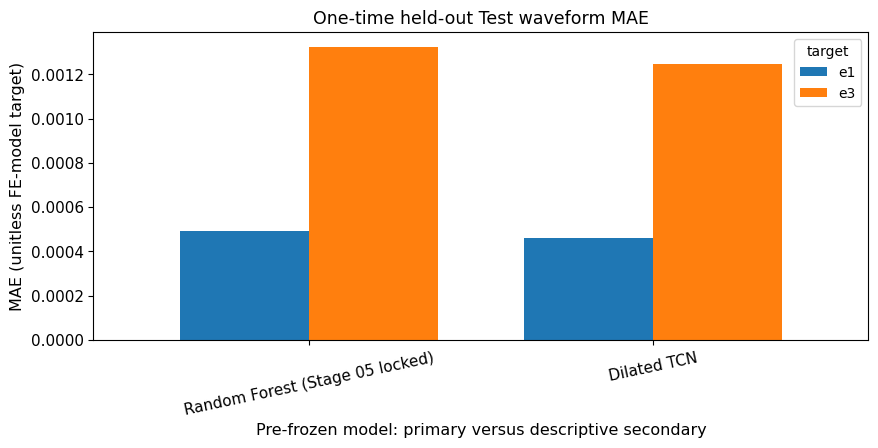

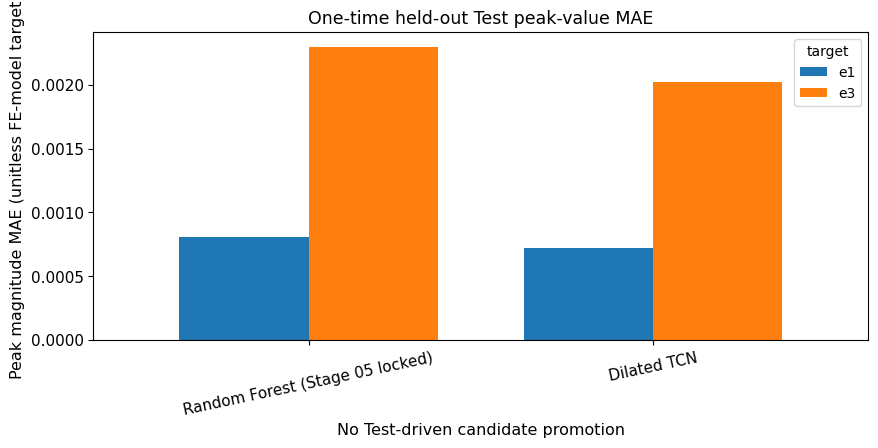

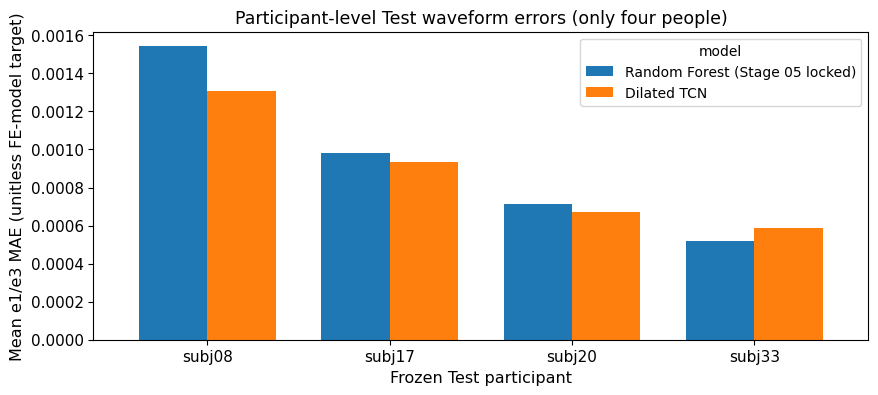

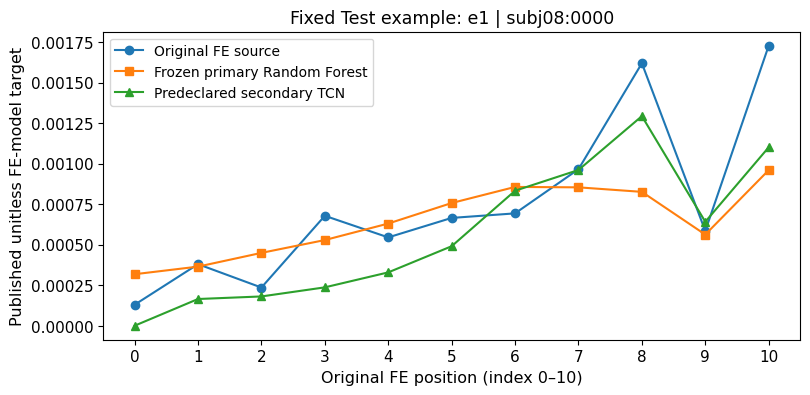

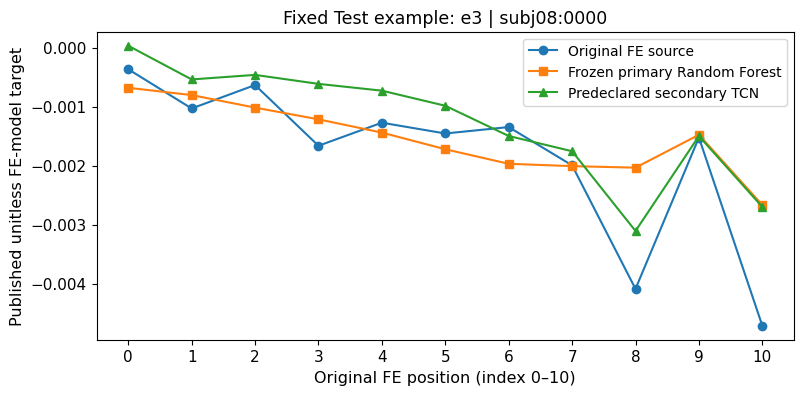

Figures are final descriptive results, never a tuning criterion.


In [10]:
# ======================= 09. Final Research Figures =========================
display_names = [EXPECTED_PRIMARY, SECONDARY]
chart = metrics_final.pivot(index="model", columns="target", values="mae")
chart = chart.reindex(display_names)
fig, ax = plt.subplots(figsize=(10, 4))
chart.plot.bar(ax=ax, width=0.75)
ax.set_title("One-time held-out Test waveform MAE")
ax.set_xlabel("Pre-frozen model: primary versus descriptive secondary")
ax.set_ylabel("MAE (unitless FE-model target)")
ax.tick_params(axis="x", rotation=12)
save_figure(fig, output_dir / "08_test_waveform_mae_comparison.png")
plt.show()

peak = metrics_final.pivot(
    index="model", columns="target", values="peak_value_mae"
).reindex(display_names)
fig, ax = plt.subplots(figsize=(10, 4))
peak.plot.bar(ax=ax, width=0.75)
ax.set_title("One-time held-out Test peak-value MAE")
ax.set_xlabel("No Test-driven candidate promotion")
ax.set_ylabel("Peak magnitude MAE (unitless FE-model target)")
ax.tick_params(axis="x", rotation=12)
save_figure(fig, output_dir / "08_test_peak_error_comparison.png")
plt.show()

per_person = subject_final.groupby(
    ["subject_id", "model"], as_index=False
)["mae"].mean().pivot(
    index="subject_id", columns="model", values="mae"
).reindex(columns=display_names)
fig, ax = plt.subplots(figsize=(10, 4))
per_person.plot.bar(ax=ax, width=0.75)
ax.set_title("Participant-level Test waveform errors (only four people)")
ax.set_xlabel("Frozen Test participant")
ax.set_ylabel("Mean e1/e3 MAE (unitless FE-model target)")
ax.tick_params(axis="x", rotation=0)
save_figure(fig, output_dir / "08_test_subject_errors.png")
plt.show()

example_i = int(np.argsort(
    test_info["local_record_key"].to_numpy()
)[0])
example_key = str(test_info.iloc[example_i]["local_record_key"])
assert example_key == sorted(test_info["local_record_key"])[0]
for j, target in enumerate(("e1", "e3")):
    fig, ax = plt.subplots(figsize=(9, 4))
    ticks = np.arange(11)
    ax.plot(ticks, y_test[example_i, :, j],
            marker="o", label="Original FE source")
    ax.plot(ticks, prediction_primary[example_i, :, j],
            marker="s", label="Frozen primary Random Forest")
    ax.plot(ticks, prediction_secondary[example_i, :, j],
            marker="^", label="Predeclared secondary TCN")
    ax.set_title(f"Fixed Test example: {target} | {example_key}")
    ax.set_xlabel("Original FE position (index 0–10)")
    ax.set_ylabel("Published unitless FE-model target")
    ax.set_xticks(ticks)
    ax.legend()
    save_figure(
        fig, output_dir / f"08_test_waveform_example_{target}.png"
    )
    plt.show()
print("Figures are final descriptive results, never a tuning criterion.")


**10. Final Quality Gate, Release Audit and Public Evidence Export**

**Final Stage 08 Quality Gate: PASSED.** All **16 committed `08_*` files** are present: the independently committed pre-Test protocol, full-development fitting manifest and 35-epoch TCN history, explicit one-time release receipt, 8,052-row Test prediction CSV, model/subject/activity/Bootstrap diagnostics, five scientific plots and final provenance gate. The final primary model was **not altered after Test**. Trained weights, numerical source cache and original source archives were not published; the source cohort is Essex, not an independent external validation cohort.


In [11]:
# ====================== 10. Stage 08 Final Quality Gate ======================
expected08 = [
    "08_frozen_final_protocol.json",
    "08_development_fit_manifest.json",
    "08_development_fit_loss_history.csv",
    "08_test_trial_predictions.csv",
    "08_test_primary_secondary_metrics.csv",
    "08_test_subject_activity_metrics.csv",
    "08_test_subject_metrics.csv",
    "08_test_task_metrics.csv",
    "08_test_subject_bootstrap.csv",
    "08_test_waveform_mae_comparison.png",
    "08_test_peak_error_comparison.png",
    "08_test_subject_errors.png",
    "08_test_waveform_example_e1.png",
    "08_test_waveform_example_e3.png",
    "08_final_test_release_receipt.json",
    "08_final_test_quality_gate.json",
]
assert protocol["protocol_status"] == "FROZEN_BEFORE_TEST"
assert file_sha256(required["freeze"]) == protocol_sha256
assert release_receipt["protocol_sha256"] == protocol_sha256
assert release_receipt["status"] == "TEST_RELEASE_CONSUMED"
assert gate07["quality_gate"] == "PASSED"
assert gate07["provisional_final_candidate_from_training_only"] == EXPECTED_PRIMARY
assert 33 == len(development_subjects)
assert 4 == len(reserved_subjects)
assert not development_subjects & reserved_subjects
assert len(long_table) == 2 * 183 * 22
assert set(metrics_final["model"]) == {EXPECTED_PRIMARY, SECONDARY}
assert set(metrics_final["role"]) == {"PRIMARY", "SECONDARY_DESCRIPTIVE"}
assert len(metrics_final) == 4
assert len(subject_final) == 16
assert boot_final["participants"].eq(4).all()
assert np.isfinite(long_table[["observed", "predicted"]]).all().all()
assert metrics_final[["mae", "rmse", "peak_value_mae"]].ge(0).all().all()
assert len(final_training_history) == 35

fit_file = output_dir / "08_development_fit_manifest.json"
fit_file.write_text(
    json.dumps(model_manifest, indent=2) + "\n", encoding="utf-8"
)
final_training_history.to_csv(
    output_dir / "08_development_fit_loss_history.csv", index=False
)
receipt_file = output_dir / "08_final_test_release_receipt.json"
receipt_file.write_text(
    json.dumps(release_receipt, indent=2) + "\n",
    encoding="utf-8",
)
missing = [name for name in expected08
           if name != FINAL_GATE_FILE and
           not (output_dir / name).is_file()]
if missing:
    raise FileNotFoundError(
        "Incomplete Stage 08 evidence: " + ", ".join(missing)
    )

evidence_hashes = {
    name: file_sha256(output_dir / name)
    for name in expected08 if name != FINAL_GATE_FILE
}
final_record = {
    "stage": "08",
    "quality_gate": "PASSED",
    "research_status": "one_time_final_test_complete",
    "frozen_protocol_sha256": protocol_sha256,
    "source_archive_sha256": gate04["original_sha256"],
    "canonical_pair_sha256": source_digest,
    "primary_selected_pre_test": EXPECTED_PRIMARY,
    "primary_selection_stage": "07_training_only",
    "secondary_fixed_descriptive": SECONDARY,
    "post_test_model_selection": False,
    "final_fit_development_subjects": 33,
    "final_fit_development_trials": 1546,
    "test_subjects": 4,
    "test_trials": 183,
    "test_evaluations_authorised": 1,
    "test_inferences_per_predeclared_model": 1,
    "test_model_fitting": False,
    "test_model_tuning": False,
    "primary_subject_balanced_mae": float(
        metrics_final.loc[
            metrics_final["model"].eq(EXPECTED_PRIMARY),
            "subject_balanced_mae"
        ].iloc[0]
    ),
    "secondary_subject_balanced_mae": float(
        metrics_final.loc[
            metrics_final["model"].eq(SECONDARY),
            "subject_balanced_mae"
        ].iloc[0]
    ),
    "published_fe_target_unit": "unitless",
    "original_fe_positions": 11,
    "source_interpolation": False,
    "bootstrap_clusters": 4,
    "bootstrap_intervals_exploratory": True,
    "clinical_validation": False,
    "independent_external_dataset": False,
    "fitted_weights_committed": False,
    "selected_compute_device": DEVICE,
    "sklearn_version": version("scikit-learn"),
    "torch_version": torch.__version__,
    "public_evidence_sha256": evidence_hashes,
}
final_gate_path = output_dir / FINAL_GATE_FILE
if final_gate_path.exists():
    raise FileExistsError("Final Test gate exists; no duplicate scoring.")
final_gate_path.write_text(
    json.dumps(final_record, indent=2) + "\n",
    encoding="utf-8",
)
assert all((output_dir / name).is_file() for name in expected08)
print("STAGE 08 | FROZEN ONE-TIME TEST QUALITY GATE: PASSED")
print("Primary choice preserved:", EXPECTED_PRIMARY)
print("Final public evidence files:", len(expected08))
print("One-time Test participants:", len(reserved_subjects))
download_outputs_from_colab(
    folder="biomechanical_load_estimation/output", stage="08",
)


STAGE 08 | FROZEN ONE-TIME TEST QUALITY GATE: PASSED
Primary choice preserved: Random Forest (Stage 05 locked)
Final public evidence files: 16
One-time Test participants: 4
------------------------------------------------------------------------
Notebook stage: 08
Files packaged: 16
  + 08_development_fit_loss_history.csv
  + 08_development_fit_manifest.json
  + 08_final_test_quality_gate.json
  + 08_final_test_release_receipt.json
  + 08_frozen_final_protocol.json
  + 08_test_peak_error_comparison.png
  + 08_test_primary_secondary_metrics.csv
  + 08_test_subject_activity_metrics.csv
  + 08_test_subject_bootstrap.csv
  + 08_test_subject_errors.png
  + 08_test_subject_metrics.csv
  + 08_test_task_metrics.csv
  + 08_test_trial_predictions.csv
  + 08_test_waveform_example_e1.png
  + 08_test_waveform_example_e3.png
  + 08_test_waveform_mae_comparison.png
Download ZIP from Colab Contents: /content/biomechanical_load_estimation_Stage_08_Outputs.zip
GitHub Commit/Push performed: NO


**11. Final Scientific Interpretation and Portfolio Handover**

**Research objective achieved at the exploratory, source-governed level.** Across Stages 01–08, the original Essex v13 MATLAB records were audited and source-aligned into **1,729 paired trials from 37 eligible participants**, with original **101×42** seven-IMU and **11×2** FE target geometry. A frozen participant-level 29/4/4 split supported Training-only model selection, diagnostic Validation, controlled three-seed robustness and one-time final evaluation on four reserved Test participants (183 trials). The work provides a reproducible research protocol and source-traceable model comparisons; it does not establish clinically verified femoral-neck loading measurements or deployment readiness.

**Preselected model and independent within-source Test.** Random Forest remained the **primary model** because it was locked before Test from the predeclared Training-only subject-balanced criterion (**0.0007950**). Both final estimators were then fitted once on the 33 Development participants, after model selection. The primary Random Forest achieved **Test subject-balanced waveform MAE 0.0009384**. The predeclared secondary Dilated TCN achieved **0.0008759**, about **6.7% lower observed MAE** on the four previously unseen Test participants. This does **not** retrospectively make Dilated TCN the primary model; the performance gap is descriptive and its exploratory paired participant-cluster interval crosses zero.

**Biomechanical prediction trade-off.** Dilated TCN's e1/e3 original-grid waveform MAEs were **0.0004611 / 0.0012482**, compared with Random Forest **0.0004926 / 0.0013249**. TCN also had lower e1/e3 peak-*value* MAE (**0.0007222 / 0.0020255**) than Random Forest (**0.0008059 / 0.0022999**), but **worse peak-*position* accuracy**: TCN **1.3497 / 1.1967** versus RF **0.9672 / 0.8415** original FE indices. Average curve error, maximum/minimum magnitude and peak location are distinct research outcomes.

**Limits and uncertainty.** Test labels came from the **same Essex original source**, although participants were separate from Development; this is participant-held-out evaluation, **not an independent external dataset**. Only four Test participants were available. The paired TCN-minus-RF Subject-Balanced MAE difference was **−0.0000625**, with exploratory 95% bootstrap interval **[−0.0001859, +0.0000431]** (2,000 whole-participant resamples). This crosses zero and is not confirmatory statistical evidence of population superiority. No measured in-vivo strain, independent FE calibration, future-cohort validation or clinical efficacy was established. Source strain targets are **unitless, FE-model-derived** and were never interpolated or converted to microstrain.

**Closure and reproducibility.** The one-time Test release receipt reports `TEST_RELEASE_CONSUMED`; the independently committed freeze was upheld; **all 16 final evidence files** and the executed Notebook 08 are available in GitHub; the final Quality Gate reports **PASSED**. The project includes eight research notebooks and a separate historical BoneNet-derivative pilot. The updated [project README](../../README.md) presents the study methods, actual final scores, source limitations and reproducibility pointers without conflating them with the pilot.

**Final study status: COMPLETE AS A SOURCE-VERIFIED EXPLORATORY RESEARCH BENCHMARK, NOT A VALIDATED CLINICAL SYSTEM.** No additional modelling notebook is required for the agreed research scope.
